In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

# Display maximum rows
pd.set_option('display.max_rows', 100)

In [4]:
# Load dataset

df = pd.read_csv("C:\\Users\\ASUS\Desktop\\DA project\\credit_card_fraud_project_dataset_.csv")

# Display first 5 records
df.head()

,transaction_id,customer_id,transaction_datetime,transaction_date,transaction_hour,merchant,merchant_category,transaction_amount,payment_method,transaction_status,city,state,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud
0,164a9d7cc011f54155e746d270d03524,CUST_0E606C366809,2019-08-04 06:51:47,2019-08-04,6,Torp-Labadie,gas_transport,64.07,Swipe,Approved,Alpharetta,GA,34.0770,-84.3033,34.697441,-85.167109,165556,0
1,62466599f86f6c65ad665f7dedea7fe4,CUST_C51B7DBC7448,2020-03-08 11:46:55,2020-03-08,11,"Greenholt, Jacobi and Gleason",gas_transport,70.77,Swipe,Approved,Lawrence,MA,42.6911,-71.1605,42.105635,-71.744017,76383,0
2,4699d5d458cc9e7b0317cad10db9ad25,CUST_6684A1525185,2020-01-12 15:57:29,2020-01-12,15,Harris Group,food_dining,21.84,Chip,Approved,Amorita,OK,36.9412,-98.2458,36.760724,-97.475362,83,0
3,0ec8223375e03bc6aa1b2c8cdb8df5cf,CUST_987E3D10EE11,2020-06-19 19:40:32,2020-06-19,19,Schuppe-Schuppe,food_dining,55.25,Swipe,Approved,Carlotta,CA,40.5070,-123.9743,40.785266,-123.638540,1139,0
4,b3011f4000f41dd273dea2283584f755,CUST_FAB1B59015E0,2019-09-12 16:02:50,2019-09-12,16,"Boehm, Block and Jakubowski",misc_pos,41.10,Online,Approved,Newberg,OR,45.3099,-122.9685,44.755678,-122.072899,28278,0


In [5]:
df.shape

(500000, 18)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   transaction_id        500000 non-null  object 
 1   customer_id           500000 non-null  object 
 2   transaction_datetime  500000 non-null  object 
 3   transaction_date      500000 non-null  object 
 4   transaction_hour      500000 non-null  int64  
 5   merchant              500000 non-null  object 
 6   merchant_category     500000 non-null  object 
 7   transaction_amount    500000 non-null  float64
 8   payment_method        500000 non-null  object 
 9   transaction_status    500000 non-null  object 
 10  city                  500000 non-null  object 
 11  state                 500000 non-null  object 
 12  customer_latitude     500000 non-null  float64
 13  customer_longitude    500000 non-null  float64
 14  merchant_latitude     500000 non-null  float64
 15  

In [7]:
df.columns

Index(['transaction_id', 'customer_id', 'transaction_datetime',
       'transaction_date', 'transaction_hour', 'merchant', 'merchant_category',
       'transaction_amount', 'payment_method', 'transaction_status', 'city',
       'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude',
       'merchant_longitude', 'city_population', 'is_fraud'],
      dtype='object')

In [8]:
df.dtypes

transaction_id           object
customer_id              object
transaction_datetime     object
transaction_date         object
transaction_hour          int64
merchant                 object
merchant_category        object
transaction_amount      float64
payment_method           object
transaction_status       object
city                     object
state                    object
customer_latitude       float64
customer_longitude      float64
merchant_latitude       float64
merchant_longitude      float64
city_population           int64
is_fraud                  int64
dtype: object

In [9]:
df.isnull().sum()

transaction_id          0
customer_id             0
transaction_datetime    0
transaction_date        0
transaction_hour        0
merchant                0
merchant_category       0
transaction_amount      0
payment_method          0
transaction_status      0
city                    0
state                   0
customer_latitude       0
customer_longitude      0
merchant_latitude       0
merchant_longitude      0
city_population         0
is_fraud                0
dtype: int64

In [10]:
df.isnull().sum().sum()

np.int64(0)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['transaction_id'].duplicated().sum()

np.int64(0)

In [13]:
df.describe()

,transaction_hour,transaction_amount,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,5.000000e+05,500000.000000
mean,12.798512,70.791888,38.541900,-90.235328,38.541193,-90.235887,8.895801e+04,0.005788
std,6.819564,175.264083,5.076745,13.764867,5.109740,13.776811,3.028615e+05,0.075858
min,0.000000,1.000000,20.027100,-165.672300,19.027804,-166.671242,2.300000e+01,0.000000
25%,7.000000,9.660000,34.668900,-96.798000,34.734409,-96.909155,7.410000e+02,0.000000
50%,14.000000,47.560000,39.354300,-87.476900,39.373487,-87.445994,2.456000e+03,0.000000
75%,19.000000,83.190000,41.940400,-80.158000,41.961716,-80.244573,2.032800e+04,0.000000
max,23.000000,28948.900000,66.693300,-67.950300,67.510267,-66.959178,2.906700e+06,1.000000


In [14]:
print("Unique Customers:", df['customer_id'].nunique())

print("Unique Merchants:", df['merchant'].nunique())

print("Merchant Categories:", df['merchant_category'].nunique())

print("Unique Cities:", df['city'].nunique())

print("Payment Methods:", df['payment_method'].nunique())

print("Transaction Status:", df['transaction_status'].nunique())

Unique Customers: 982
Unique Merchants: 693
Merchant Categories: 14
Unique Cities: 893
Payment Methods: 4
Transaction Status: 4


In [15]:
df['is_fraud'].value_counts()

is_fraud
0    497106
1      2894
Name: count, dtype: int64

In [16]:
fraud_percentage = (df['is_fraud'].sum() / len(df)) * 100

print("Fraud Percentage:", round(fraud_percentage, 2), "%")

Fraud Percentage: 0.58 %


In [17]:
# Create a copy of original dataset

df_clean = df.copy()

# Check shape

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (500000, 18)
Working Dataset: (500000, 18)


In [18]:
# Convert transaction_datetime

df_clean['transaction_datetime'] = pd.to_datetime(
    df_clean['transaction_datetime'],
    errors='coerce'
)

# Convert transaction_date

df_clean['transaction_date'] = pd.to_datetime(
    df_clean['transaction_date'],
    errors='coerce'
)

# Check datatypes

df_clean[['transaction_datetime', 'transaction_date']].dtypes

transaction_datetime    datetime64[ns]
transaction_date        datetime64[ns]
dtype: object

In [19]:
# Check missing values

missing_values = df_clean.isnull().sum()

print(missing_values)

transaction_id          0
customer_id             0
transaction_datetime    0
transaction_date        0
transaction_hour        0
merchant                0
merchant_category       0
transaction_amount      0
payment_method          0
transaction_status      0
city                    0
state                   0
customer_latitude       0
customer_longitude      0
merchant_latitude       0
merchant_longitude      0
city_population         0
is_fraud                0
dtype: int64


In [20]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

Total Missing Values: 0


In [21]:
# Check duplicate rows

print("Duplicate Rows:", df_clean.duplicated().sum())

# Check duplicate transaction IDs

print("Duplicate Transaction IDs:",
      df_clean['transaction_id'].duplicated().sum())

Duplicate Rows: 0
Duplicate Transaction IDs: 0


In [22]:
# Check negative transaction amounts

negative_amounts = df_clean[
    df_clean['transaction_amount'] < 0
]

print("Negative Transactions:", len(negative_amounts))

Negative Transactions: 0


In [23]:
zero_amounts = df_clean[
    df_clean['transaction_amount'] == 0
]

print("Zero Amount Transactions:", len(zero_amounts))

Zero Amount Transactions: 0


In [24]:
# Check unique fraud values

print(df_clean['is_fraud'].unique())

[0 1]


In [25]:
invalid_fraud = df_clean[
    ~df_clean['is_fraud'].isin([0, 1])
]

print("Invalid Fraud Records:", len(invalid_fraud))

Invalid Fraud Records: 0


In [26]:
invalid_hours = df_clean[
    (df_clean['transaction_hour'] < 0) |
    (df_clean['transaction_hour'] > 23)
]

print("Invalid Transaction Hours:", len(invalid_hours))

Invalid Transaction Hours: 0


In [27]:
invalid_customer_location = df_clean[
    (~df_clean['customer_latitude'].between(-90, 90)) |
    (~df_clean['customer_longitude'].between(-180, 180))
]

print("Invalid Customer Locations:",
      len(invalid_customer_location))

Invalid Customer Locations: 0


In [28]:
invalid_merchant_location = df_clean[
    (~df_clean['merchant_latitude'].between(-90, 90)) |
    (~df_clean['merchant_longitude'].between(-180, 180))
]

print("Invalid Merchant Locations:",
      len(invalid_merchant_location))

Invalid Merchant Locations: 0


In [29]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   transaction_id        500000 non-null  object        
 1   customer_id           500000 non-null  object        
 2   transaction_datetime  500000 non-null  datetime64[ns]
 3   transaction_date      500000 non-null  datetime64[ns]
 4   transaction_hour      500000 non-null  int64         
 5   merchant              500000 non-null  object        
 6   merchant_category     500000 non-null  object        
 7   transaction_amount    500000 non-null  float64       
 8   payment_method        500000 non-null  object        
 9   transaction_status    500000 non-null  object        
 10  city                  500000 non-null  object        
 11  state                 500000 non-null  object        
 12  customer_latitude     500000 non-null  float64       
 13 

In [30]:
data_quality = pd.DataFrame({

    'Check': [
        'Total Records',
        'Total Columns',
        'Missing Values',
        'Duplicate Rows',
        'Duplicate Transaction IDs',
        'Negative Transaction Amounts',
        'Zero Transaction Amounts',
        'Invalid Fraud Values',
        'Invalid Transaction Hours',
        'Invalid Customer Locations',
        'Invalid Merchant Locations'
    ],

    'Result': [
        len(df_clean),
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean['transaction_id'].duplicated().sum(),
        (df_clean['transaction_amount'] < 0).sum(),
        (df_clean['transaction_amount'] == 0).sum(),
        (~df_clean['is_fraud'].isin([0, 1])).sum(),
        (~df_clean['transaction_hour'].between(0, 23)).sum(),
        len(invalid_customer_location),
        len(invalid_merchant_location)
    ]
})

# Display Data Quality Summary

data_quality

,Check,Result
0,Total Records,500000
1,Total Columns,18
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Transaction IDs,0
5,Negative Transaction Amounts,0
6,Zero Transaction Amounts,0
7,Invalid Fraud Values,0
8,Invalid Transaction Hours,0
9,Invalid Customer Locations,0


In [31]:
# Export cleaned dataset

df_clean.to_csv(
    "credit_card_fraud_cleaned.csv",
    index=False
)

print("Cleaned Dataset Exported Successfully!")

Cleaned Dataset Exported Successfully!


In [32]:
# Transaction Amount Statistical Analysis

df_clean['transaction_amount'].describe()

count    500000.000000
mean         70.791888
std         175.264083
min           1.000000
25%           9.660000
50%          47.560000
75%          83.190000
max       28948.900000
Name: transaction_amount, dtype: float64

In [33]:
average_amount = df_clean['transaction_amount'].mean()

print("Average Transaction Amount:", round(average_amount, 2))

Average Transaction Amount: 70.79


In [34]:
median_amount = df_clean['transaction_amount'].median()

print("Median Transaction Amount:", round(median_amount, 2))

Median Transaction Amount: 47.56


In [35]:
print("Minimum Transaction Amount:",
      df_clean['transaction_amount'].min())

print("Maximum Transaction Amount:",
      df_clean['transaction_amount'].max())

Minimum Transaction Amount: 1.0
Maximum Transaction Amount: 28948.9


In [36]:
total_amount = df_clean['transaction_amount'].sum()

print("Total Transaction Amount:", round(total_amount, 2))

Total Transaction Amount: 35395944.09


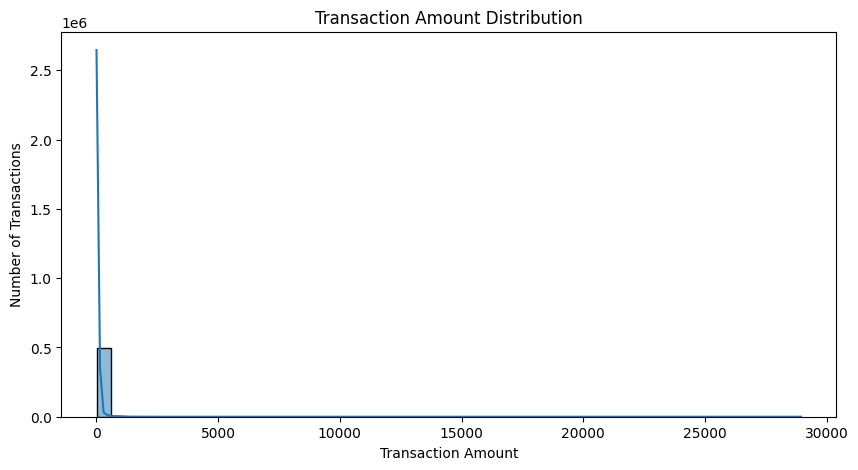

In [37]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='transaction_amount',
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

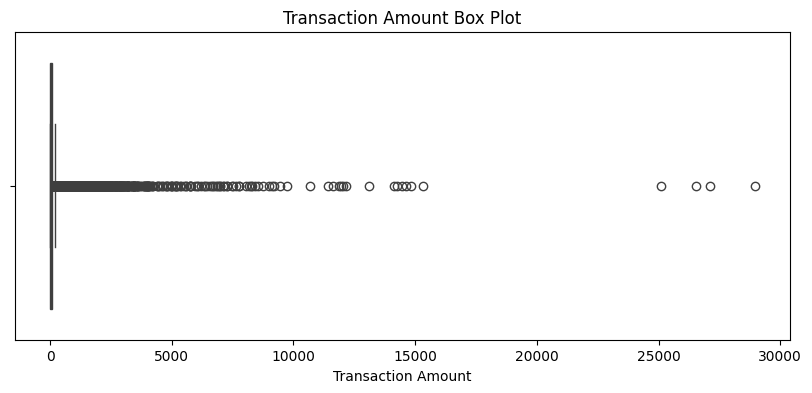

In [38]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_clean['transaction_amount'])

plt.title("Transaction Amount Box Plot")
plt.xlabel("Transaction Amount")

plt.show()

In [40]:
fraud_counts = df_clean['is_fraud'].value_counts()

print("Non-Fraud Transactions:", fraud_counts[0])
print("Fraud Transactions:", fraud_counts[1])

Non-Fraud Transactions: 497106
Fraud Transactions: 2894


In [41]:
fraud_percentage = (df_clean['is_fraud'].mean()) * 100

print("Fraud Percentage:", round(fraud_percentage, 2), "%")

Fraud Percentage: 0.58 %


In [42]:
fraud_amount = df_clean[
    df_clean['is_fraud'] == 1
]['transaction_amount'].sum()

print("Total Fraudulent Amount:", round(fraud_amount, 2))

Total Fraudulent Amount: 1581912.11


In [43]:
non_fraud_amount = df_clean[
    df_clean['is_fraud'] == 0
]['transaction_amount'].sum()

print("Total Non-Fraud Amount:", round(non_fraud_amount, 2))

Total Non-Fraud Amount: 33814031.98


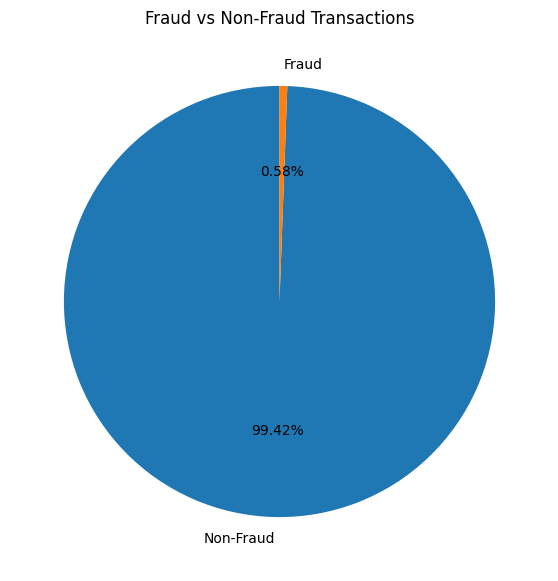

In [44]:
plt.figure(figsize=(7, 7))

plt.pie(
    fraud_counts,
    labels=['Non-Fraud', 'Fraud'],
    autopct='%1.2f%%',
    startangle=90
)

plt.title("Fraud vs Non-Fraud Transactions")

plt.show()

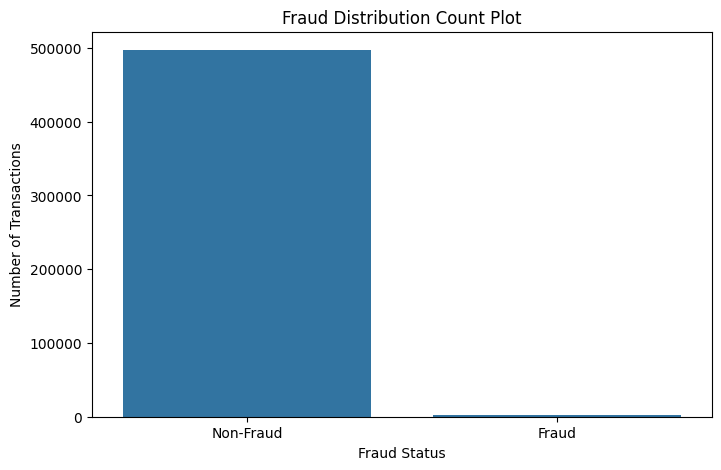

In [45]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='is_fraud'
)

plt.title("Fraud Distribution Count Plot")
plt.xlabel("Fraud Status")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

In [46]:
hourly_transactions = df_clean.groupby(
    'transaction_hour'
).size()

print(hourly_transactions)

transaction_hour
0     16379
1     16560
2     16407
3     16627
4     16143
5     16316
6     16361
7     16376
8     16454
9     16142
10    16259
11    16212
12    25004
13    25171
14    25025
15    25458
16    25381
17    25142
18    25640
19    25049
20    24847
21    25151
22    25952
23    25944
dtype: int64


In [47]:
busiest_hour = hourly_transactions.idxmax()

print("Busiest Transaction Hour:", busiest_hour)
print("Total Transactions:", hourly_transactions.max())

Busiest Transaction Hour: 22
Total Transactions: 25952


In [48]:
lowest_hour = hourly_transactions.idxmin()

print("Lowest Transaction Hour:", lowest_hour)
print("Total Transactions:", hourly_transactions.min())

Lowest Transaction Hour: 9
Total Transactions: 16142


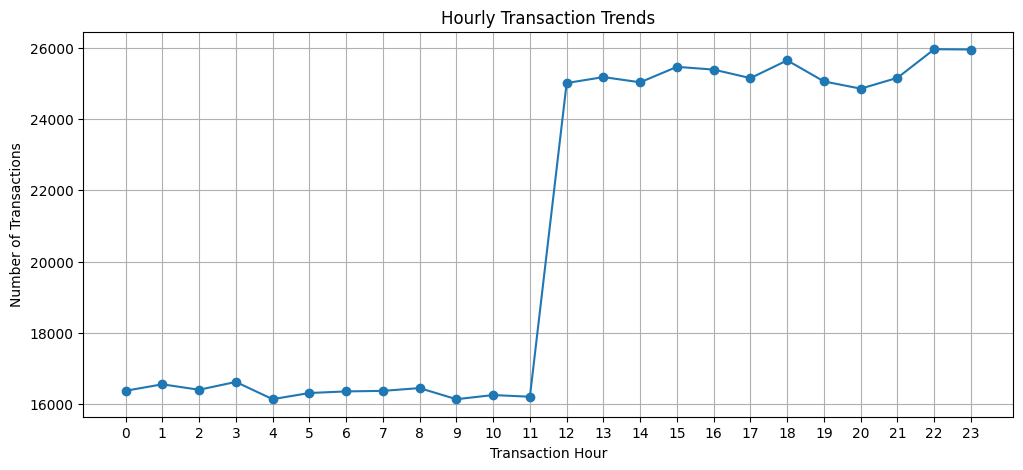

In [49]:
plt.figure(figsize=(12, 5))

hourly_transactions.plot(
    kind='line',
    marker='o'
)

plt.title("Hourly Transaction Trends")
plt.xlabel("Transaction Hour")
plt.ylabel("Number of Transactions")

plt.xticks(range(24))
plt.grid(True)

plt.show()

In [50]:
hourly_fraud = df_clean.groupby(
    'transaction_hour'
)['is_fraud'].sum()

print(hourly_fraud)

transaction_hour
0     237
1     248
2     241
3     235
4      19
5      25
6      17
7      21
8      10
9      15
10     20
11     13
12     21
13     29
14     24
15     34
16     35
17     27
18     27
19     29
20     25
21     33
22    761
23    748
Name: is_fraud, dtype: int64


In [51]:
max_fraud_hour = hourly_fraud.idxmax()

print("Hour with Maximum Fraud:", max_fraud_hour)
print("Fraud Transactions:", hourly_fraud.max())

Hour with Maximum Fraud: 22
Fraud Transactions: 761


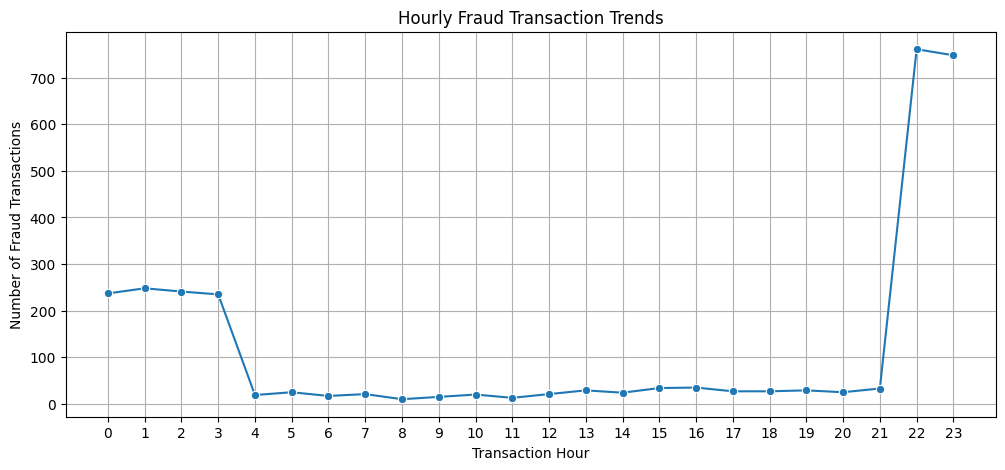

In [52]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_fraud.index,
    y=hourly_fraud.values,
    marker='o'
)

plt.title("Hourly Fraud Transaction Trends")
plt.xlabel("Transaction Hour")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(range(24))
plt.grid(True)

plt.show()

In [53]:
print("Maximum Fraud Hour:", hourly_fraud.idxmax())

print("Maximum Fraud Transactions:", hourly_fraud.max())

print("Minimum Fraud Hour:", hourly_fraud.idxmin())

print("Minimum Fraud Transactions:", hourly_fraud.min())

Maximum Fraud Hour: 22
Maximum Fraud Transactions: 761
Minimum Fraud Hour: 8
Minimum Fraud Transactions: 10


In [55]:
# Calculate fraud percentage by hour

hourly_fraud_rate = (
    df_clean.groupby('transaction_hour')['is_fraud'].mean() * 100
)

print(hourly_fraud_rate.round(2))

transaction_hour
0     1.45
1     1.50
2     1.47
3     1.41
4     0.12
5     0.15
6     0.10
7     0.13
8     0.06
9     0.09
10    0.12
11    0.08
12    0.08
13    0.12
14    0.10
15    0.13
16    0.14
17    0.11
18    0.11
19    0.12
20    0.10
21    0.13
22    2.93
23    2.88
Name: is_fraud, dtype: float64


In [56]:
# Top 10 hours with highest fraud percentage

hourly_fraud_rate.sort_values(
    ascending=False
).head(10)

transaction_hour
22    2.932337
23    2.883133
1     1.497585
2     1.468885
0     1.446975
3     1.413364
5     0.153224
16    0.137898
15    0.133553
21    0.131208
Name: is_fraud, dtype: float64

In [57]:
customer_spending = df_clean.groupby(
    'customer_id'
)['transaction_amount'].sum()

customer_spending.head(10)

customer_id
CUST_00686B4DD655     9371.40
CUST_008693EDCF12    76890.77
CUST_00B9614BD546    54231.36
CUST_00C57352E3E0     1316.70
CUST_00E1AEADC44E    16197.06
CUST_00E2AD8FED12    47148.64
CUST_011DF1128BB6    14528.52
CUST_0173389B22B3    40702.34
CUST_019CE791D540    50087.46
CUST_01DEBD46FF3B    53097.09
Name: transaction_amount, dtype: float64

In [58]:
top_customers = customer_spending.sort_values(
    ascending=False
).head(10)

print(top_customers)

customer_id
CUST_3F128965B93D    121905.68
CUST_A3A62304E057    114755.28
CUST_FA46922D7B8A    113715.86
CUST_8715D9E40DC2    112027.96
CUST_CD81464D3E96    111833.19
CUST_5B9E1E38487F    111076.21
CUST_82BC011F90F9    110738.66
CUST_E2097D89A4B2    110403.78
CUST_B82BF3D7EBC1    110297.57
CUST_B4FA0AABA467    108153.52
Name: transaction_amount, dtype: float64


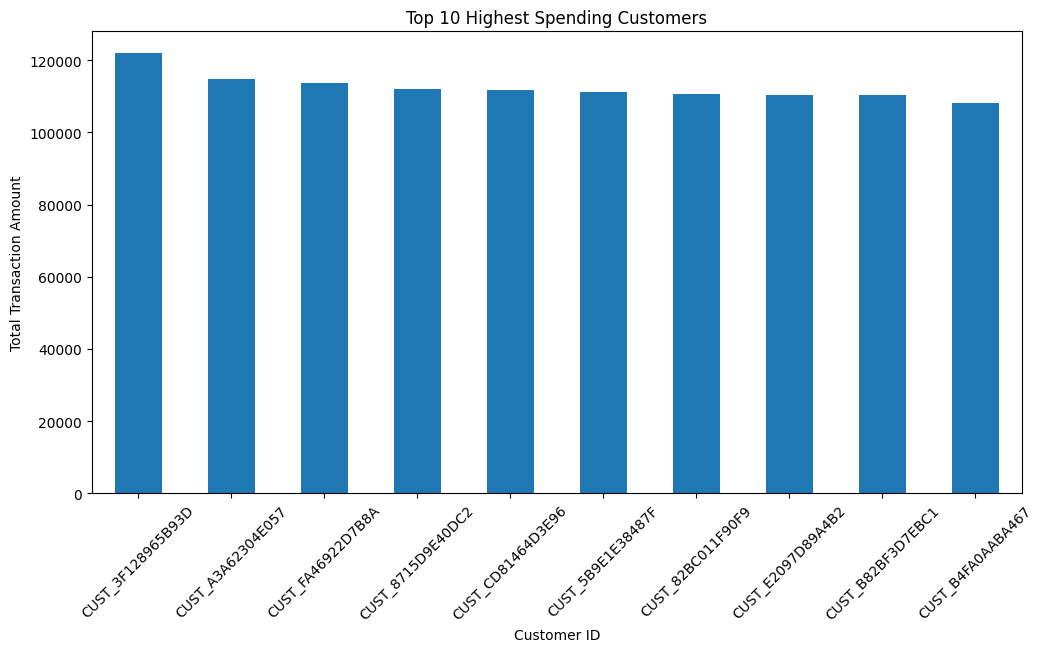

In [59]:
plt.figure(figsize=(12, 6))

top_customers.plot(kind='bar')

plt.title("Top 10 Highest Spending Customers")
plt.xlabel("Customer ID")
plt.ylabel("Total Transaction Amount")

plt.xticks(rotation=45)
plt.show()

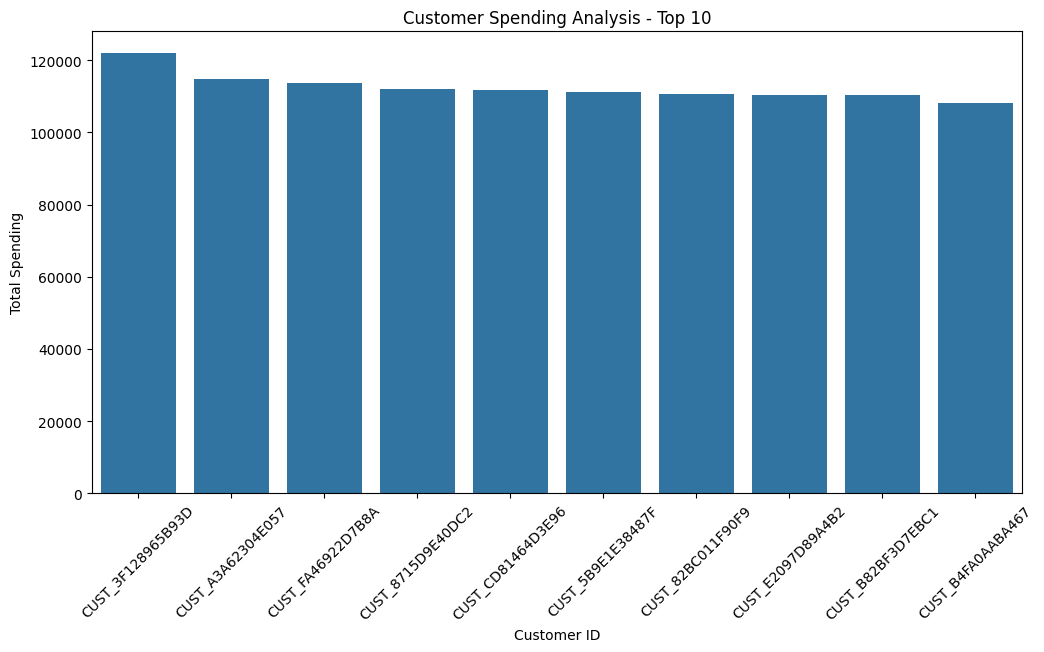

In [60]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_customers.index,
    y=top_customers.values
)

plt.title("Customer Spending Analysis - Top 10")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")

plt.xticks(rotation=45)
plt.show()

In [61]:
category_transactions = df_clean.groupby(
    'merchant_category'
).size().sort_values(ascending=False)

print(category_transactions)

merchant_category
gas_transport     50785
grocery_pos       47682
home              47281
shopping_pos      45050
kids_pets         43642
shopping_net      37539
entertainment     36454
food_dining       35118
personal_care     34941
health_fitness    33112
misc_pos          30678
misc_net          24447
grocery_net       17647
travel            15624
dtype: int64


In [62]:
category_amount = df_clean.groupby(
    'merchant_category'
)['transaction_amount'].sum().sort_values(
    ascending=False
)

print(category_amount)

merchant_category
grocery_pos       5575257.81
shopping_pos      3594166.47
shopping_net      3407909.83
gas_transport     3223400.84
home              2772278.76
kids_pets         2520498.55
entertainment     2354194.17
misc_net          1996390.57
misc_pos          1898913.79
travel            1848202.58
health_fitness    1794560.25
food_dining       1791253.86
personal_care     1675878.67
grocery_net        943037.94
Name: transaction_amount, dtype: float64


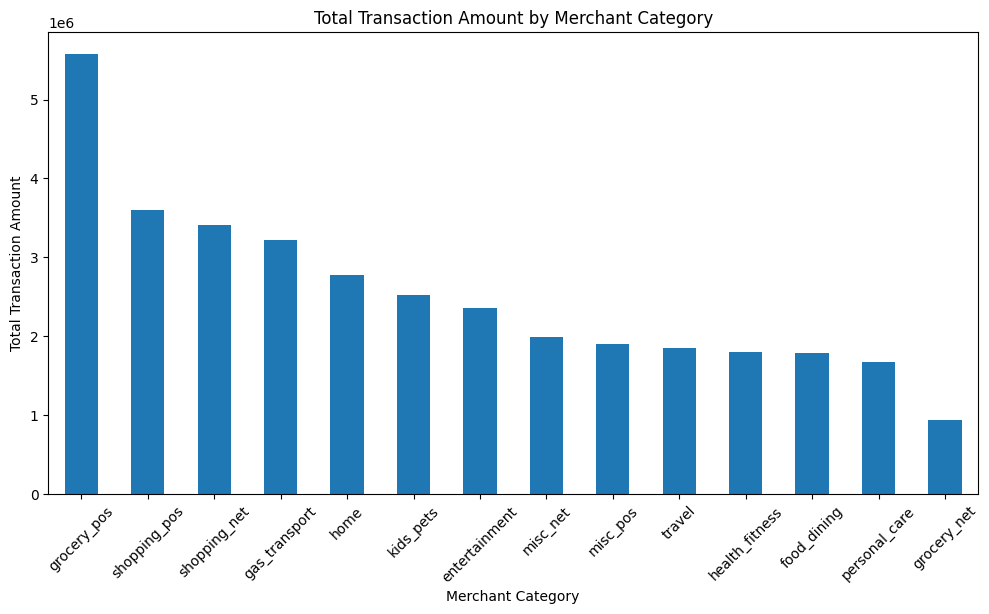

In [63]:
plt.figure(figsize=(12, 6))

category_amount.plot(kind='bar')

plt.title("Total Transaction Amount by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Total Transaction Amount")

plt.xticks(rotation=45)
plt.show()

In [64]:
category_fraud = df_clean.groupby(
    'merchant_category'
)['is_fraud'].sum().sort_values(ascending=False)

print(category_fraud)

merchant_category
shopping_net      693
grocery_pos       641
misc_net          372
shopping_pos      326
gas_transport     247
home               90
misc_pos           89
entertainment      89
kids_pets          85
personal_care      84
food_dining        49
health_fitness     44
travel             43
grocery_net        42
Name: is_fraud, dtype: int64


In [65]:
category_fraud_rate = (
    df_clean.groupby('merchant_category')['is_fraud'].mean() * 100
)

print(category_fraud_rate.sort_values(ascending=False).round(2))

merchant_category
shopping_net      1.85
misc_net          1.52
grocery_pos       1.34
shopping_pos      0.72
gas_transport     0.49
misc_pos          0.29
travel            0.28
entertainment     0.24
personal_care     0.24
grocery_net       0.24
kids_pets         0.19
home              0.19
food_dining       0.14
health_fitness    0.13
Name: is_fraud, dtype: float64


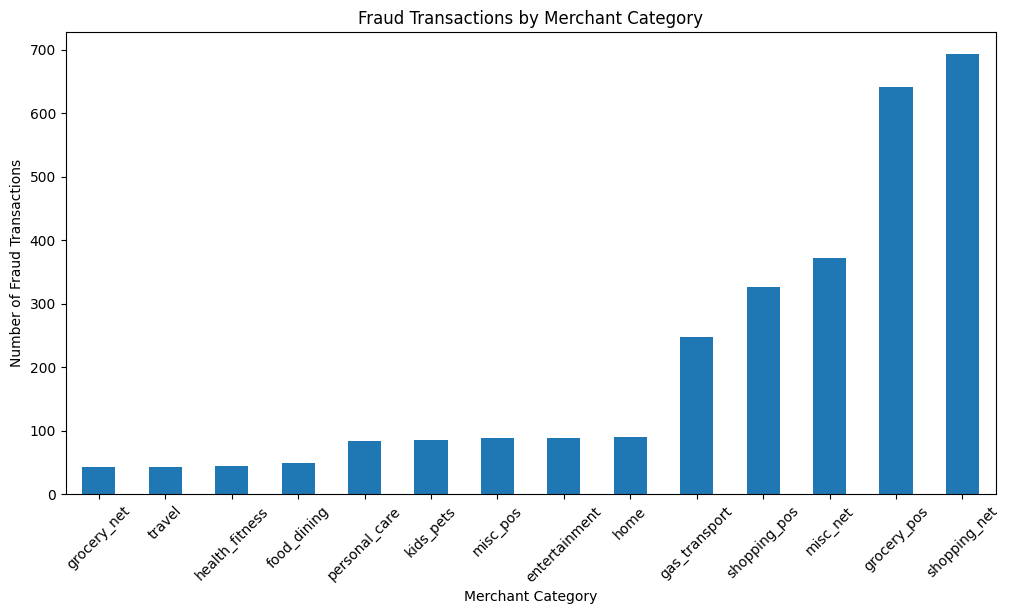

In [66]:
plt.figure(figsize=(12, 6))

category_fraud.sort_values().plot(kind='bar')

plt.title("Fraud Transactions by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45)
plt.show()

In [67]:
merchant_summary = df_clean.groupby(
    'merchant_category'
).agg(
    total_transactions=('transaction_id', 'count'),
    total_amount=('transaction_amount', 'sum'),
    average_amount=('transaction_amount', 'mean'),
    fraud_transactions=('is_fraud', 'sum')
)

merchant_summary['fraud_percentage'] = (
    merchant_summary['fraud_transactions'] /
    merchant_summary['total_transactions']
) * 100

merchant_summary = merchant_summary.sort_values(
    by='total_amount',
    ascending=False
)

merchant_summary.round(2)

,total_transactions,total_amount,average_amount,fraud_transactions,fraud_percentage
merchant_category,,,,,
grocery_pos,47682,5575257.81,116.93,641,1.34
shopping_pos,45050,3594166.47,79.78,326,0.72
shopping_net,37539,3407909.83,90.78,693,1.85
gas_transport,50785,3223400.84,63.47,247,0.49
home,47281,2772278.76,58.63,90,0.19
kids_pets,43642,2520498.55,57.75,85,0.19
entertainment,36454,2354194.17,64.58,89,0.24
misc_net,24447,1996390.57,81.66,372,1.52
misc_pos,30678,1898913.79,61.90,89,0.29


In [68]:
state_transactions = df_clean.groupby(
    'state'
).size().sort_values(ascending=False)

print(state_transactions.head(10))

state
TX    36559
NY    32123
PA    30733
CA    21646
MI    17996
OH    17978
IL    16612
FL    16423
AL    15863
MO    14786
dtype: int64


In [69]:
city_transactions = df_clean.groupby(
    'city'
).size().sort_values(ascending=False)

print(city_transactions.head(10))

city
Birmingham     2201
Utica          2002
San Antonio    1972
Phoenix        1955
Meridian       1931
Thomas         1809
Warren         1790
Cleveland      1767
Conway         1729
Houston        1648
dtype: int64


In [70]:
state_fraud_rate = (
    df_clean.groupby('state')['is_fraud'].mean() * 100
)

print(
    state_fraud_rate.sort_values(
        ascending=False
    ).head(10).round(2)
)

state
DE    100.00
RI      3.76
AK      2.32
OR      0.88
CO      0.79
NH      0.76
NE      0.74
OH      0.72
ME      0.72
MN      0.71
Name: is_fraud, dtype: float64


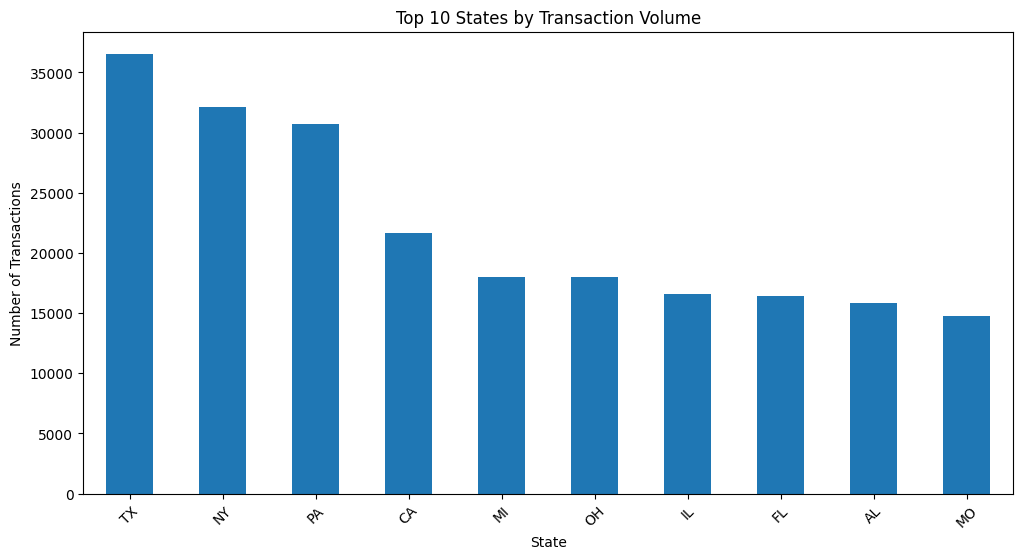

In [71]:
plt.figure(figsize=(12, 6))

state_transactions.head(10).plot(kind='bar')

plt.title("Top 10 States by Transaction Volume")
plt.xlabel("State")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.show()

In [73]:
state_fraud = df_clean.groupby(
    'state'
)['is_fraud'].sum().sort_values(ascending=False)

print(state_fraud.head(10))

state
NY    208
TX    198
PA    165
OH    130
CA    116
IL    106
FL     98
MO     89
MN     87
MI     87
Name: is_fraud, dtype: int64


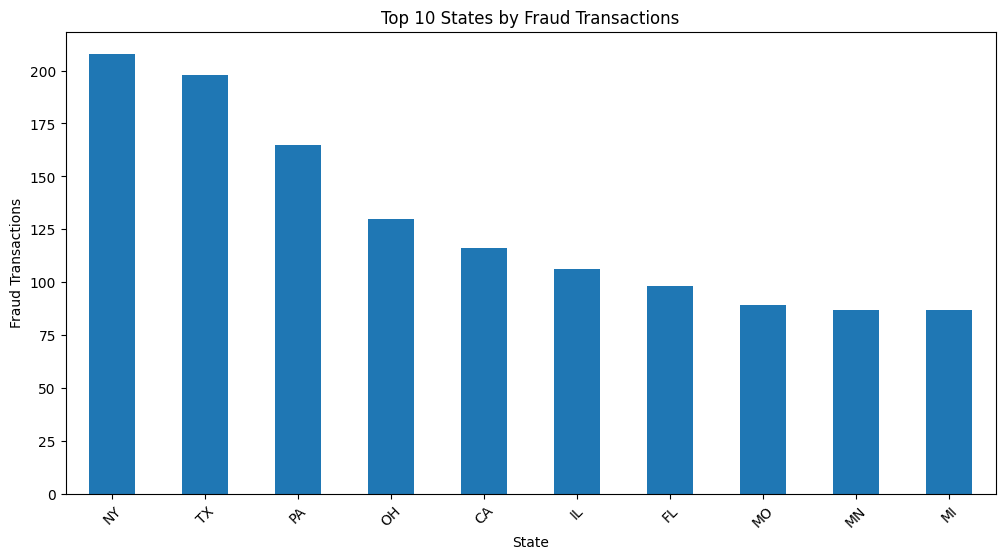

In [74]:
plt.figure(figsize=(12, 6))

state_fraud.head(10).plot(kind='bar')

plt.title("Top 10 States by Fraud Transactions")
plt.xlabel("State")
plt.ylabel("Fraud Transactions")

plt.xticks(rotation=45)
plt.show()

In [75]:
# Convert latitude and longitude into radians

lat1 = np.radians(df_clean['customer_latitude'])
lon1 = np.radians(df_clean['customer_longitude'])

lat2 = np.radians(df_clean['merchant_latitude'])
lon2 = np.radians(df_clean['merchant_longitude'])

# Calculate differences

dlat = lat2 - lat1
dlon = lon2 - lon1

# Haversine formula

a = (
    np.sin(dlat / 2) ** 2 +
    np.cos(lat1) * np.cos(lat2) *
    np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a))

# Calculate distance in kilometers

df_clean['transaction_distance_km'] = 6371 * c

df_clean[['customer_id',
          'merchant',
          'transaction_distance_km']].head()

,customer_id,merchant,transaction_distance_km
0,CUST_0E606C366809,Torp-Labadie,105.082803
1,CUST_C51B7DBC7448,"Greenholt, Jacobi and Gleason",80.832549
2,CUST_6684A1525185,Harris Group,71.428769
3,CUST_987E3D10EE11,Schuppe-Schuppe,41.950497
4,CUST_FAB1B59015E0,"Boehm, Block and Jakubowski",93.545073


In [76]:
distance_analysis = df_clean.groupby(
    'is_fraud'
)['transaction_distance_km'].agg(
    ['mean', 'median', 'min', 'max']
)

distance_analysis

,mean,median,min,max
is_fraud,,,,
0,76.137423,78.250304,0.137004,152.117173
1,75.955565,77.372833,1.449529,142.782157


In [77]:
suspicious_locations = df_clean[
    df_clean['transaction_distance_km'] > 100
]

print("Transactions Above 100 KM:",
      len(suspicious_locations))

suspicious_locations.head(10)

Transactions Above 100 KM: 117007


,transaction_id,customer_id,transaction_datetime,transaction_date,transaction_hour,merchant,merchant_category,transaction_amount,payment_method,transaction_status,city,state,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud,transaction_distance_km
0,164a9d7cc011f54155e746d270d03524,CUST_0E606C366809,2019-08-04 06:51:47,2019-08-04,6,Torp-Labadie,gas_transport,64.07,Swipe,Approved,Alpharetta,GA,34.0770,-84.3033,34.697441,-85.167109,165556,0,105.082803
7,ab80394d97272ebf1df2d2e222338620,CUST_7923FA903CFB,2020-01-05 21:34:07,2020-01-05,21,"Roberts, Ryan and Smith",personal_care,84.43,Online,Approved,Napa,CA,38.4549,-122.2564,37.565785,-122.964903,94014,0,116.734876
9,0c8c2c7b2092900971db8a183ae55a44,CUST_24FDA4A8E102,2019-07-08 14:06:39,2019-07-08,14,"Prosacco, Kreiger and Kovacek",home,82.87,Online,Approved,Naples,FL,26.1184,-81.7361,27.034387,-82.716767,276002,0,141.012250
18,e03bb5c5160cc0a4a22eb2f6614585d1,CUST_708105AB17AE,2020-02-03 15:05:43,2020-02-03,15,Schimmel-Olson,kids_pets,48.53,Swipe,Approved,Turner,MT,48.8328,-108.3961,47.917148,-108.270143,192,0,102.239976
19,c1c4e4a7edccdaacb9dc753dccf7824a,CUST_B10466E01E4A,2020-03-09 09:31:43,2020-03-09,9,"Parisian, Schiller and Altenwerth",misc_net,104.73,Online,Approved,Clune,PA,40.5503,-79.3237,41.508340,-79.353323,168,0,106.558162
23,2bc35a00470ed088aea6d3d1ce46e4f9,CUST_060C9D1B5B4C,2019-05-04 05:13:54,2019-05-04,5,Gislason Group,misc_pos,49.48,Online,Approved,Dayton,OH,39.8355,-84.2613,39.181717,-83.399320,479994,0,103.697593
24,ca91ed85b37f0056fe9ce507016e7b05,CUST_94A7FC350589,2019-10-05 13:52:14,2019-10-05,13,"Berge, Kautzer and Harris",personal_care,12.52,Swipe,Approved,Metairie,LA,29.9975,-90.2146,30.885137,-90.806217,137067,0,113.835108
27,74712df6abedd9944d09e1ae330819d3,CUST_2D33C5BA84AB,2020-03-29 01:47:58,2020-03-29,1,Huel Ltd,misc_net,3.07,Swipe,Approved,Luzerne,MI,44.6001,-84.2931,45.424309,-83.500321,864,0,110.828028
35,02cb9bbe4641b1940c79473fce8747d6,CUST_9F73C3118D5E,2020-05-14 22:09:33,2020-05-14,22,Block Group,misc_pos,4.87,Chip,Approved,Methuen,MA,42.7280,-71.1810,41.965819,-72.092693,47249,0,113.119585
47,0c4765065fde20f48870f8a2f454cf6c,CUST_C881EA443AEE,2019-04-04 01:20:08,2019-04-04,1,"Bahringer, Schoen and Corkery",shopping_pos,120.49,Online,Approved,Lahoma,OK,36.3850,-98.0727,35.521896,-98.439266,1078,0,101.485986


In [78]:
suspicious_fraud = suspicious_locations['is_fraud'].value_counts()

print("Non-Fraud:", suspicious_fraud.get(0, 0))
print("Fraud:", suspicious_fraud.get(1, 0))

Non-Fraud: 116329
Fraud: 678


In [79]:
suspicious_fraud_percentage = (
    suspicious_locations['is_fraud'].mean() * 100
)

print(
    "Fraud Percentage in Distant Transactions:",
    round(suspicious_fraud_percentage, 2), "%"
)

Fraud Percentage in Distant Transactions: 0.58 %


In [80]:

distance_comparison = df_clean.groupby(
    'is_fraud'
)['transaction_distance_km'].agg(
    ['count', 'mean', 'median', 'max']
)

distance_comparison

,count,mean,median,max
is_fraud,,,,
0,497106,76.137423,78.250304,152.117173
1,2894,75.955565,77.372833,142.782157


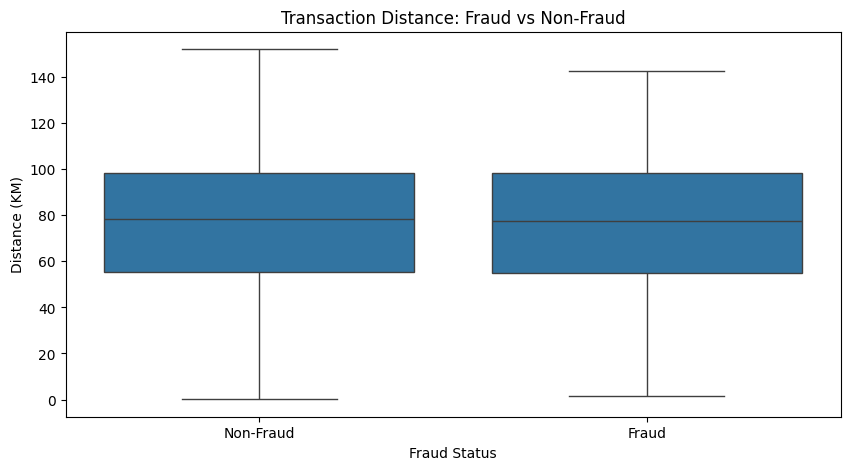

In [81]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='is_fraud',
    y='transaction_distance_km'
)

plt.title("Transaction Distance: Fraud vs Non-Fraud")
plt.xlabel("Fraud Status")
plt.ylabel("Distance (KM)")

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()

In [82]:
numerical_columns = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

print(numerical_columns)

Index(['transaction_hour', 'transaction_amount', 'customer_latitude',
       'customer_longitude', 'merchant_latitude', 'merchant_longitude',
       'city_population', 'is_fraud', 'transaction_distance_km'],
      dtype='object')


In [83]:
correlation_matrix = df_clean[numerical_columns].corr()

correlation_matrix

,transaction_hour,transaction_amount,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud,transaction_distance_km
transaction_hour,1.000000,-0.019373,-0.011140,-0.004423,-0.011012,-0.004422,0.019913,0.015751,-0.000328
transaction_amount,-0.019373,1.000000,-0.003173,-0.000389,-0.003032,-0.000316,0.005987,0.207148,-0.001098
customer_latitude,-0.011140,-0.003173,1.000000,-0.015494,0.993592,-0.015455,-0.156070,0.003133,-0.072731
customer_longitude,-0.004423,-0.000389,-0.015494,1.000000,-0.015383,0.999119,-0.050570,-0.000315,0.006312
merchant_latitude,-0.011012,-0.003032,0.993592,-0.015383,1.000000,-0.015347,-0.154982,0.003013,-0.072723
merchant_longitude,-0.004422,-0.000316,-0.015455,0.999119,-0.015347,1.000000,-0.050543,-0.000345,0.006328
city_population,0.019913,0.005987,-0.156070,-0.050570,-0.154982,-0.050543,1.000000,0.002325,0.009962
is_fraud,0.015751,0.207148,0.003133,-0.000315,0.003013,-0.000345,0.002325,1.000000,-0.000474
transaction_distance_km,-0.000328,-0.001098,-0.072731,0.006312,-0.072723,0.006328,0.009962,-0.000474,1.000000


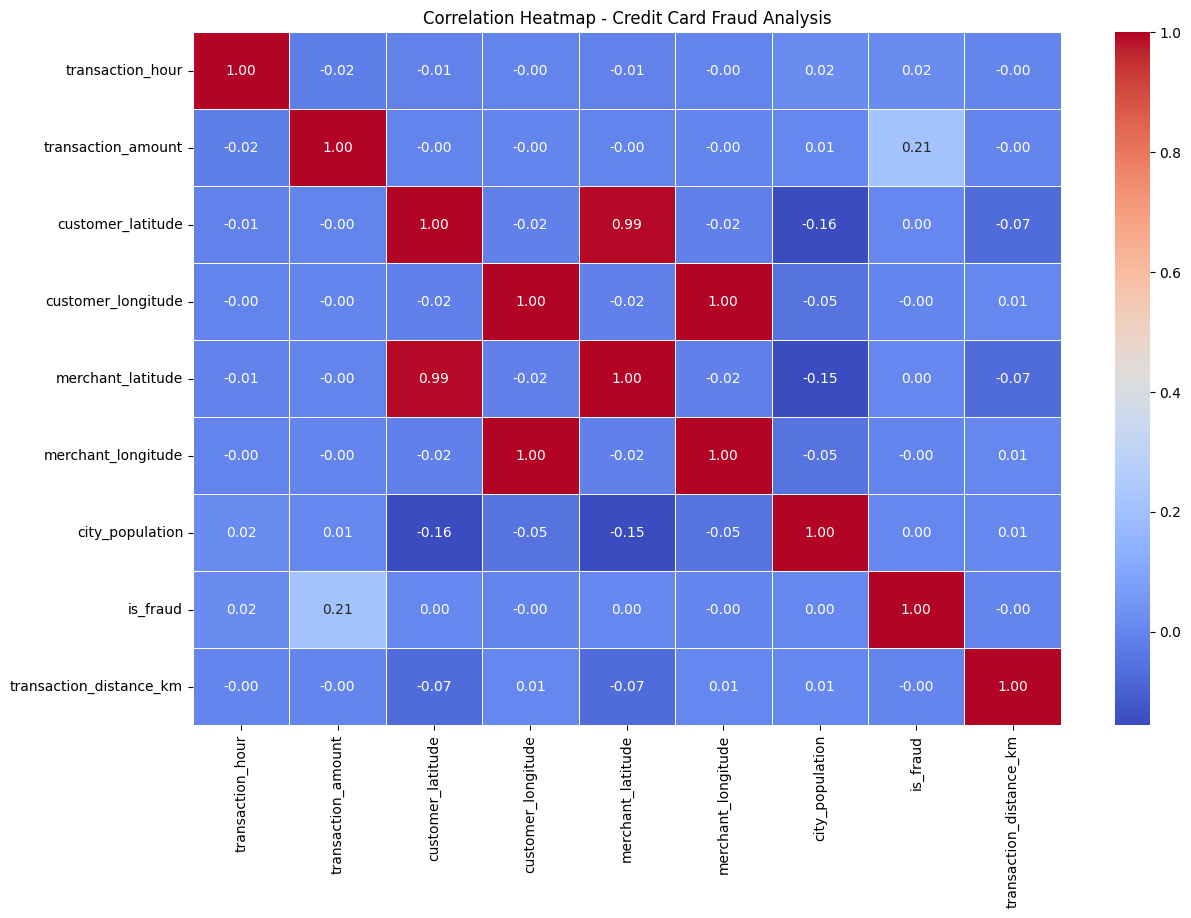

In [84]:
plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - Credit Card Fraud Analysis")

plt.show()

In [85]:
fraud_correlation = correlation_matrix['is_fraud'].sort_values(
    ascending=False
)

print(fraud_correlation)

is_fraud                   1.000000
transaction_amount         0.207148
transaction_hour           0.015751
customer_latitude          0.003133
merchant_latitude          0.003013
city_population            0.002325
customer_longitude        -0.000315
merchant_longitude        -0.000345
transaction_distance_km   -0.000474
Name: is_fraud, dtype: float64


In [86]:
fraud_correlation.sort_values(
    ascending=False
).head(10)

is_fraud                   1.000000
transaction_amount         0.207148
transaction_hour           0.015751
customer_latitude          0.003133
merchant_latitude          0.003013
city_population            0.002325
customer_longitude        -0.000315
merchant_longitude        -0.000345
transaction_distance_km   -0.000474
Name: is_fraud, dtype: float64

In [87]:
fraud_correlation.sort_values().head(10)

transaction_distance_km   -0.000474
merchant_longitude        -0.000345
customer_longitude        -0.000315
city_population            0.002325
merchant_latitude          0.003013
customer_latitude          0.003133
transaction_hour           0.015751
transaction_amount         0.207148
is_fraud                   1.000000
Name: is_fraud, dtype: float64

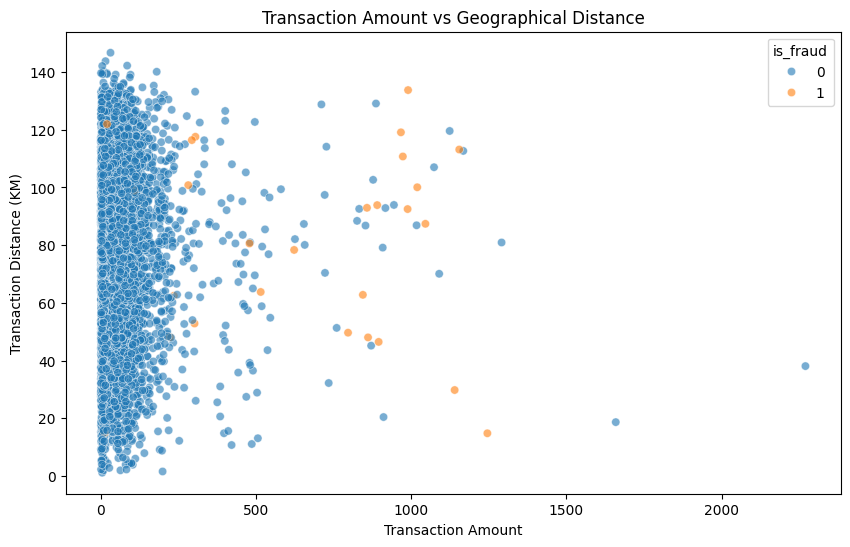

In [88]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean.sample(5000, random_state=42),
    x='transaction_amount',
    y='transaction_distance_km',
    hue='is_fraud',
    alpha=0.6
)

plt.title("Transaction Amount vs Geographical Distance")
plt.xlabel("Transaction Amount")
plt.ylabel("Transaction Distance (KM)")

plt.show()

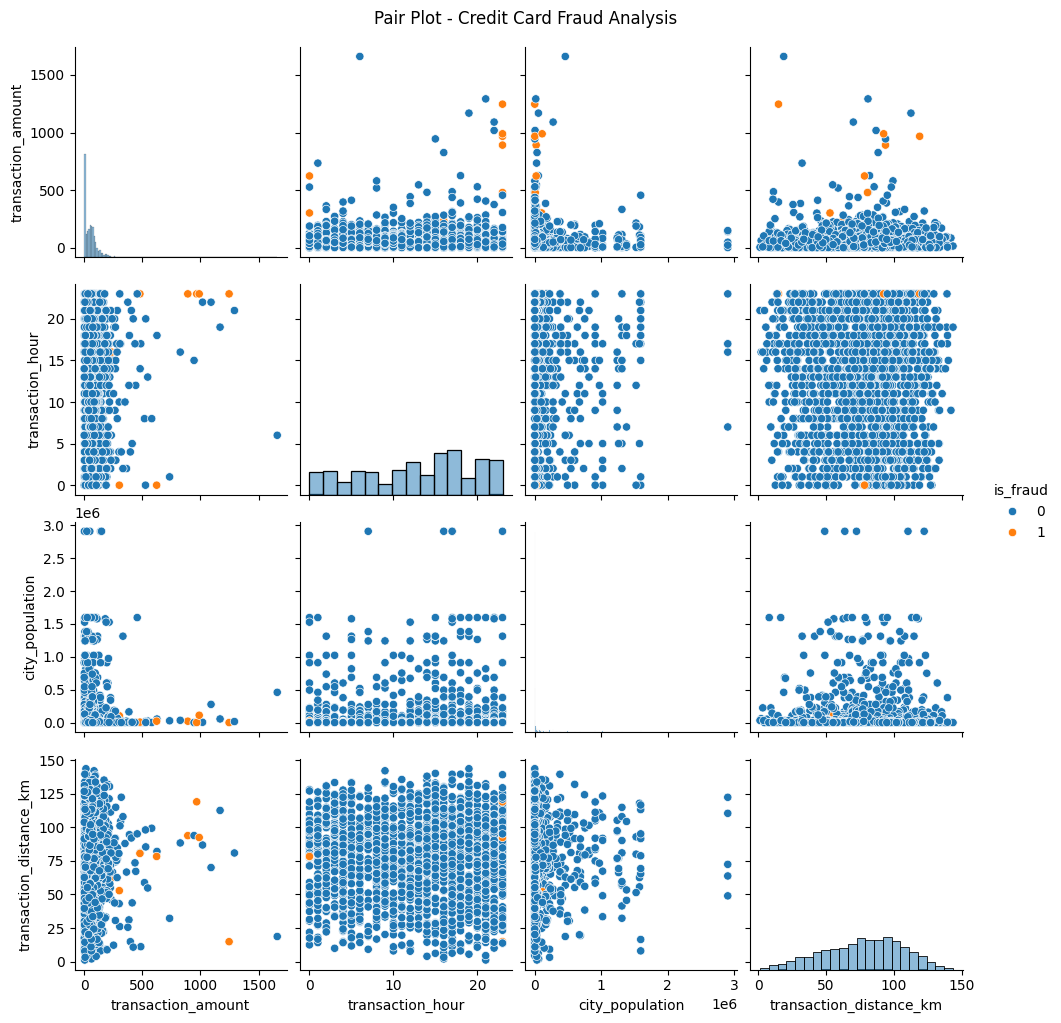

In [89]:
pairplot_data = df_clean[
    [
        'transaction_amount',
        'transaction_hour',
        'city_population',
        'transaction_distance_km',
        'is_fraud'
    ]
].sample(2000, random_state=42)

sns.pairplot(
    pairplot_data,
    hue='is_fraud',
    diag_kind='hist'
)

plt.suptitle(
    "Pair Plot - Credit Card Fraud Analysis",
    y=1.02
)

plt.show()

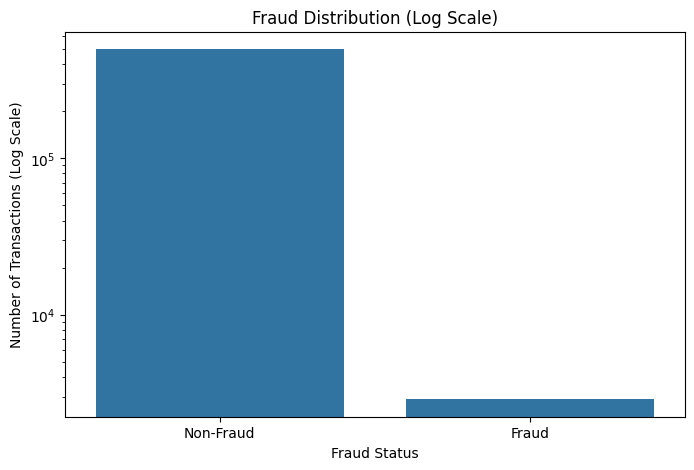

In [90]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='is_fraud'
)

plt.yscale('log')

plt.title("Fraud Distribution (Log Scale)")
plt.xlabel("Fraud Status")
plt.ylabel("Number of Transactions (Log Scale)")

plt.xticks([0, 1], ['Non-Fraud', 'Fraud'])

plt.show()